In [1]:
print("Welcome to BioSeq AI!")
print("DNA Sequence Classification using Machine Learning")
print("Project setup successful.")

Welcome to BioSeq AI!
DNA Sequence Classification using Machine Learning
Project setup successful.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import ConfusionMatrixDisplay

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
import urllib.request

url = "https://archive.ics.uci.edu/static/public/67/molecular+biology+promoter+gene+sequences.zip"

urllib.request.urlretrieve(url, "promoter_dataset.zip")

print("Dataset downloaded successfully!")

Dataset downloaded successfully!


In [4]:
import zipfile
import os

with zipfile.ZipFile("promoter_dataset.zip", "r") as zip_ref:
    zip_ref.extractall("promoter_data")

print("Dataset extracted successfully!")

for root, dirs, files in os.walk("promoter_data"):
    for file in files:
        print(os.path.join(root, file))

Dataset extracted successfully!
promoter_data/promoters.names
promoter_data/Index
promoter_data/promoters.theory
promoter_data/promoters.data


In [5]:
with open("promoter_data/promoters.data", "r") as file:
    for i in range(10):
        print(file.readline().rstrip())

+,S10,		tactagcaatacgcttgcgttcggtggttaagtatgtataatgcgcgggcttgtcgt
+,AMPC,		tgctatcctgacagttgtcacgctgattggtgtcgttacaatctaacgcatcgccaa
+,AROH,		gtactagagaactagtgcattagcttatttttttgttatcatgctaaccacccggcg
+,DEOP2,	aattgtgatgtgtatcgaagtgtgttgcggagtagatgttagaatactaacaaactc
+,LEU1_TRNA,	tcgataattaactattgacgaaaagctgaaaaccactagaatgcgcctccgtggtag
+,MALEFG,	aggggcaaggaggatggaaagaggttgccgtataaagaaactagagtccgtttaggt
+,MALK,		cagggggtggaggatttaagccatctcctgatgacgcatagtcagcccatcatgaat
+,RECA,		tttctacaaaacacttgatactgtatgagcatacagtataattgcttcaacagaaca
+,RPOB,		cgacttaatatactgcgacaggacgtccgttctgtgtaaatcgcaatgaaatggttt
+,RRNAB_P1,	ttttaaatttcctcttgtcaggccggaataactccctataatgcgccaccactgaca


In [7]:
import pandas as pd

data = []

with open("promoter_data/promoters.data", "r") as file:
    for line in file:
        parts = line.strip().split(",")

        if len(parts) >= 3:
            label = parts[0].strip()
            gene_name = parts[1].strip()
            sequence = parts[2].strip().lower()

            if label in ["+", "-"] and sequence:
                data.append({
                    "label": label,
                    "gene_name": gene_name,
                    "sequence": sequence
                })

df = pd.DataFrame(data)

print("Dataset loaded successfully!")
print("Total sequences:", len(df))
print("\nFirst 5 rows:")
print(df.head())

print("\nClass distribution:")
print(df["label"].value_counts())

Dataset loaded successfully!
Total sequences: 106

First 5 rows:
  label  gene_name                                           sequence
0     +        S10  tactagcaatacgcttgcgttcggtggttaagtatgtataatgcgc...
1     +       AMPC  tgctatcctgacagttgtcacgctgattggtgtcgttacaatctaa...
2     +       AROH  gtactagagaactagtgcattagcttatttttttgttatcatgcta...
3     +      DEOP2  aattgtgatgtgtatcgaagtgtgttgcggagtagatgttagaata...
4     +  LEU1_TRNA  tcgataattaactattgacgaaaagctgaaaaccactagaatgcgc...

Class distribution:
label
+    53
-    53
Name: count, dtype: int64


In [8]:
from sklearn.feature_extraction.text import CountVectorizer

vectorizer = CountVectorizer(
    analyzer="char",
    ngram_range=(2, 3)
)

X = vectorizer.fit_transform(df["sequence"])
y = df["label"]

print("Feature extraction completed!")
print("Number of DNA sequences:", X.shape[0])
print("Number of features:", X.shape[1])
print("Labels:", sorted(y.unique()))

Feature extraction completed!
Number of DNA sequences: 106
Number of features: 80
Labels: ['+', '-']


In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 79
Testing samples: 27


In [10]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=2000)

model.fit(X_train, y_train)

print("BioSeq AI model trained successfully!")

BioSeq AI model trained successfully!


In [11]:
from sklearn.metrics import accuracy_score, classification_report

# Testing data par predictions
y_pred = model.predict(X_test)

# Accuracy calculate karna
accuracy = accuracy_score(y_test, y_pred)

print("========== BioSeq AI Results ==========")
print(f"Model Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

========== BioSeq AI Results ==========
Model Accuracy: 92.59%

Classification Report:
              precision    recall  f1-score   support

           +       0.88      1.00      0.93        14
           -       1.00      0.85      0.92        13

    accuracy                           0.93        27
   macro avg       0.94      0.92      0.93        27
weighted avg       0.94      0.93      0.93        27



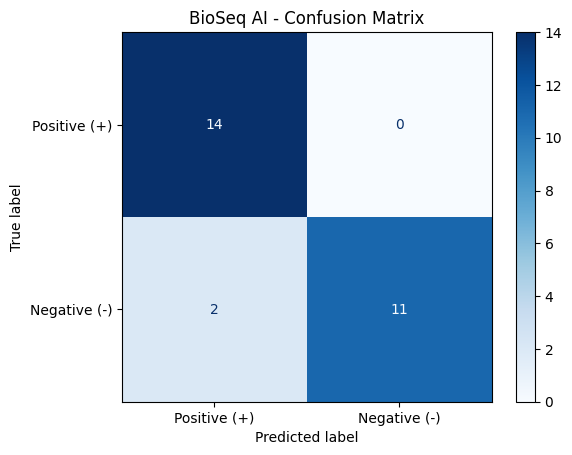

In [12]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred, labels=["+", "-"])

display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Positive (+)", "Negative (-)"]
)

display_matrix.plot(cmap="Blues")
plt.title("BioSeq AI - Confusion Matrix")
plt.show()

In [13]:
# Sample DNA sequence
new_sequence = "tactagcaatacgcttgcgttcggtggttaagtatgtataatgcgcgggcttgtcgt"

# Sequence ko model ke required format mein convert karo
new_features = vectorizer.transform([new_sequence])

# Prediction
prediction = model.predict(new_features)[0]

print("========== BioSeq AI Prediction ==========")
print("DNA Sequence:", new_sequence)
print("Predicted Class:", prediction)

========== BioSeq AI Prediction ==========
DNA Sequence: tactagcaatacgcttgcgttcggtggttaagtatgtataatgcgcgggcttgtcgt
Predicted Class: +


In [15]:
!pip -q install gradio


In [16]:
import gradio as gr
print("Gradio version:", gr.__version__)

Gradio version: 6.30.0


In [17]:
import gradio as gr
from collections import Counter

def predict_dna(sequence):
    sequence = sequence.strip().lower()

    if not sequence:
        return "Please enter a DNA sequence.", ""

    if any(base not in "atgc" for base in sequence):
        return "Invalid input! Use only A, T, G and C.", ""

    if len(sequence) < 3:
        return "Sequence too short. Enter at least 3 bases.", ""

    # Extract the same features used during training
    features = vectorizer.transform([sequence])

    # Predict the class
    prediction = model.predict(features)[0]

    # Calculate nucleotide composition
    counts = Counter(sequence.upper())
    total = len(sequence)

    stats = "\n".join([
        f"Sequence length: {total} bases",
        f"A: {counts['A']} ({counts['A']/total*100:.1f}%)",
        f"T: {counts['T']} ({counts['T']/total*100:.1f}%)",
        f"G: {counts['G']} ({counts['G']/total*100:.1f}%)",
        f"C: {counts['C']} ({counts['C']/total*100:.1f}%)"
    ])

    result = (
        f"Predicted class: {prediction}\n\n"
        "This is a dataset-specific ML classification, "
        "not a medical diagnosis."
    )

    return result, stats


with gr.Blocks(title="BioSeq AI") as demo:

    gr.Markdown("# 🧬 BioSeq AI")
    gr.Markdown(
        "### DNA Sequence Classification Using Machine Learning"
    )

    gr.Markdown(
        "Enter a DNA sequence containing A, T, G and C."
    )

    dna_input = gr.Textbox(
        label="DNA Sequence",
        placeholder="Example: ATGCGTACGTAGCTAG",
        lines=3
    )

    predict_button = gr.Button("🔬 Classify DNA Sequence")

    prediction_output = gr.Textbox(
        label="Classification Result"
    )

    stats_output = gr.Textbox(
        label="DNA Sequence Statistics"
    )

    predict_button.click(
        fn=predict_dna,
        inputs=dna_input,
        outputs=[prediction_output, stats_output]
    )

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://9a887e52a4ff5783f4.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


       BIOSEQ AI - FINAL EVALUATION
Total dataset samples: 106
Training samples: 79
Testing samples: 27
Final model accuracy: 92.59%

Classification Report:
              precision    recall  f1-score   support

           +       0.88      1.00      0.93        14
           -       1.00      0.85      0.92        13

    accuracy                           0.93        27
   macro avg       0.94      0.92      0.93        27
weighted avg       0.94      0.93      0.93        27



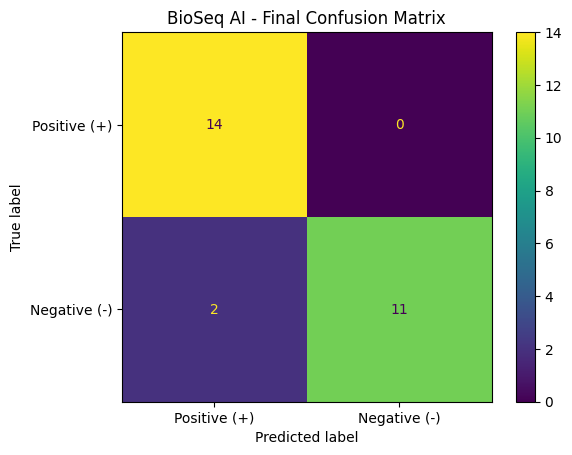

Final model training and evaluation completed!


In [18]:
# BioSeq AI - Final Machine Learning Pipeline

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Split the original DNA sequences before feature extraction
X_train_seq, X_test_seq, y_train, y_test = train_test_split(
    df["sequence"],
    df["label"],
    test_size=0.25,
    random_state=42,
    stratify=df["label"]
)

# Create a complete machine learning pipeline
final_model = make_pipeline(
    CountVectorizer(analyzer="char", ngram_range=(2, 3)),
    LogisticRegression(max_iter=2000)
)

# Train the model
final_model.fit(X_train_seq, y_train)

# Evaluate on unseen test sequences
final_predictions = final_model.predict(X_test_seq)
final_accuracy = accuracy_score(y_test, final_predictions)

print("=" * 45)
print("       BIOSEQ AI - FINAL EVALUATION")
print("=" * 45)
print(f"Total dataset samples: {len(df)}")
print(f"Training samples: {len(X_train_seq)}")
print(f"Testing samples: {len(X_test_seq)}")
print(f"Final model accuracy: {final_accuracy * 100:.2f}%")
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        final_predictions,
        zero_division=0
    )
)

# Display the confusion matrix
cm = confusion_matrix(
    y_test,
    final_predictions,
    labels=["+", "-"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Positive (+)", "Negative (-)"]
)

disp.plot()
plt.title("BioSeq AI - Final Confusion Matrix")
plt.show()

print("Final model training and evaluation completed!")

In [19]:
import gradio as gr
from collections import Counter

def predict_dna(sequence):
    sequence = sequence.strip().upper()

    if not sequence:
        return "Please enter a DNA sequence.", ""

    if any(base not in "ATGC" for base in sequence):
        return "Invalid input! Use only A, T, G and C.", ""

    if len(sequence) < 3:
        return "Sequence too short. Enter at least 3 bases.", ""

    # Use the final trained pipeline
    prediction = final_model.predict([sequence])[0]

    # Calculate nucleotide statistics
    counts = Counter(sequence)
    total = len(sequence)

    stats = "\n".join([
        f"Sequence length: {total} bases",
        f"A: {counts['A']} ({counts['A']/total*100:.1f}%)",
        f"T: {counts['T']} ({counts['T']/total*100:.1f}%)",
        f"G: {counts['G']} ({counts['G']/total*100:.1f}%)",
        f"C: {counts['C']} ({counts['C']/total*100:.1f}%)"
    ])

    result = (
        f"Predicted class: {prediction}\n\n"
        "This is an experimental, dataset-specific "
        "machine learning prediction, not a medical diagnosis."
    )

    return result, stats


with gr.Blocks(title="BioSeq AI") as demo:
    gr.Markdown("# 🧬 BioSeq AI")
    gr.Markdown("### DNA Sequence Classification Using Machine Learning")
    gr.Markdown(
        "Enter a DNA sequence containing A, T, G and C "
        "to obtain an experimental classification."
    )

    dna_input = gr.Textbox(
        label="DNA Sequence",
        placeholder="Example: ATGCGTACGTAGCTAG",
        lines=3
    )

    predict_button = gr.Button("🔬 Classify DNA Sequence")

    prediction_output = gr.Textbox(label="Classification Result")
    stats_output = gr.Textbox(label="DNA Sequence Statistics")

    predict_button.click(
        fn=predict_dna,
        inputs=dna_input,
        outputs=[prediction_output, stats_output]
    )

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://7d889b68aea47835ec.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
